### 1\Agent根据传入的模型字符串，自主创建模型对象

<class 'langgraph.graph.state.CompiledStateGraph'>


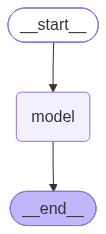

In [6]:
from langchain.agents import create_agent
from dotenv import load_dotenv
load_dotenv(override=True)

agent = create_agent(model = "openrouter:qwen3.8-max")
print(type(agent))

from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [13]:
from langchain_tavily import TavilySearch
from dotenv import load_dotenv
import os
load_dotenv(override=True)
web_search = TavilySearch(
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
    max_results=2
)
#这是一个高度封装的网络搜索工具，可以直接调用：
res = web_search.invoke("请问2026年足球世界杯有哪些参赛队？")
for item in res.get("results", []):
    print(item.get("content", ""))


1 A组
  + 1.1 墨西哥
  + 1.2 南非
  + 1.3 韩国
  + 1.4 捷克
 2 B组
  + 2.1 加拿大
  + 2.2 波黑
  + 2.3 卡塔尔
  + 2.4 瑞士
 3 C组
  + 3.1 巴西
  + 3.2 摩洛哥
  + 3.3 海地
  + 3.4 苏格兰
 4 D组
  + 4.1 美国
  + 4.2 巴拉圭
  + 4.3 澳大利亚
  + 4.4 土耳其
 5 E组
  + 5.1 德国
  + 5.2 库拉索
  + 5.3 科特迪瓦
  + 5.4 厄瓜多尔
 6 F组
  + 6.1 荷兰
  + 6.2 日本
  + 6.3 瑞典
  + 6.4 突尼西亚
 7 G组
  + 7.1 比利时
  + 7.2 埃及
  + 7.3 伊朗
  + 7.4 新西兰
 8 H组
  + 8.1 西班牙
  + 8.2 佛得角
  + 8.3 沙特阿拉伯
  + 8.4 乌拉圭
 9 I组
  + 9.1 法国
  + 9.2 塞内加尔
  + 9.3 伊拉克
  + 9.4 挪威
 10 J组
  + 10.1 阿根廷 [...] 10 J组
  + 10.1 阿根廷
  + 10.2 阿尔及利亚
  + 10.3 奥地利
  + 10.4 约旦
 11 K组
  + 11.1 葡萄牙
  + 11.2 民主刚果
  + 11.3 乌兹别克斯坦
  + 11.4 哥伦比亚
 12 L组
  + 12.1 英格兰
  + 12.2 克罗地亚
  + 12.3 加纳
  + 12.4 巴拿马
 13 注释
 14 参考文献
 15 外部链接 [...] | 18 | 前锋 "前锋 (足球)") | 吴贤揆 | (2001-04-12)2001年4月12日（25岁） | 27 | 6 | 土耳其足球协会 贝西克塔斯 |
| 19 | 中场 | 李刚仁 | (2001-02-19)2001年2月19日（25岁） | 47 | 11 | 法国足球协会 巴黎圣日耳曼 |
| 20 | 中场 | 杨贤俊 | (2002-05-25)2002年5月25日（24岁） | 9 | 0 | 苏格兰足球协会 凯尔特人 |
| 21 | 门将 "守门员 (足球)") | 赵贤祐 | (1991-09-25)1991年9月25日（34岁

### 3\工具调用（内置工具和外部工具接入）

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from rich import print as rprint

@tool(parse_docstring=True)
def get_weather(city: str) -> str:
    """
    天气查询工具

    Args:
        city: 城市名称
    """

    return f"{city}的天气为晴朗，25°C。"

agent = create_agent(
model = model,
tools=[get_weather]
)
resp = agent.invoke( {
"messages": [
{"role": "system", "content": "你是一个天气查询助手，只回答天气相关的问题，其他问题请直接回答：我不清楚这问题答案。"},
{"role": "user", "content": "北京的天气怎么样？"}
# {"role": "user", "content": "100加上50等于多少？"}
]
})
rprint(resp)


In [19]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain_tavily import TavilySearch
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint
# 1.模型初始化
model = init_chat_model(
    model = "openai:qwen3.8-max",
    api_key = os.getenv("BAILIAN_API_KEY") ,
    base_url = os.getenv("BAILIAN_API_URL"),
)

web_search = TavilySearch(
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
    max_results=2
)

# 3.创建Agent
agent = create_agent(
    model=model,
    tools=[web_search]
#system_prompt="你是一名多才多艺的智能助手，可以调用工具帮助用户解决问题。"
)

# 4.运行Agent获得结果
result = agent.invoke(
{"messages": [{"role": "user", "content": "请帮我查询2024年诺贝尔物理学奖得主是谁？"}]}
)
# rprint(result)
print(result['messages'][-1].content)


## 2024年诺贝尔物理学奖得主

**获奖者（两人平分奖金）：**

| 得主 | 国籍 | 所属机构 |
|---|---|---|
| **约翰·J·霍普菲尔德**（John J. Hopfield，生于1933年） | 美国 | 普林斯顿大学 |
| **杰弗里·E·辛顿**（Geoffrey E. Hinton，生于1947年，又译"欣顿"） | 英国 / 加拿大 | 多伦多大学 |

**获奖理由：**
> "for foundational discoveries and inventions that enable machine learning with artificial neural networks"
> —— 表彰他们**使人工神经网络机器学习成为可能的基础性发现与发明** [1][2][3]

**关键信息：**
- **宣布时间**：2024年10月8日，由瑞典皇家科学院公布 [1]
- **颁奖典礼**：2024年12月10日（诺贝尔逝世纪念日）在斯德哥尔摩举行 [1]
- **核心贡献**：两人的研究主要始于20世纪80年代，他们**将物理学（尤其是统计物理）的概念应用于计算建模**，构建了受大脑结构与功能启发的计算模型 [3][4]
  - 霍普菲尔德于1982年提出了**联想记忆网络**，即著名的"**霍普菲尔德网络**"（Hopfield network），能够存储并重建图像与数据中的模式 [4]
  - 辛顿在此基础之上发展了**玻尔兹曼机**（Boltzmann machine，与Terrence Sejnowski合作），运用统计物理方法，成为后来深度学习和现代大型神经网络的基石之一 [4]

**一点背景补充：**
这次颁奖在当时引发了广泛讨论——因为这是诺贝尔物理学奖首次授予**人工智能领域**的研究者。辛顿被称为"AI教父"，他曾在获奖前后多次公开呼吁关注AI的安全与风险问题 [2]。有趣的是，紧随其后公布的2024年诺贝尔化学奖也部分授予了AI相关研究（DeepMind的Demis Hassabis与John Jumper），使2024年被称为"AI的诺贝尔年"。

**参考来源：**
1. [nobelists.org — 2024年诺贝尔物理学奖得主](https://www.nobelists.org

### 4\重试机制

In [8]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint
load_dotenv(override=True)
flag = 0
@tool
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    global flag
    flag += 1
    
    if flag < 3:
# raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}今天天气挺好"

messages = [
SystemMessage(
    """
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]

agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})
# rprint(response)
for msg in response["messages"]:
    msg.pretty_print()


================================ System Message ================================


    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    
================================ Human Message =================================

你好，杭州今天的天气如何？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_fa8b9566d3d447f994943c82)
 Call ID: call_fa8b9566d3d447f994943c82
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_dd2f5567a2dd41f6a9666b25)
 Call ID: call_dd2f5567a2dd41f6a9666b25
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试
===================

### 5\设置名字

### 6\系统提示词

### 7\结构化输出

In [3]:
from langchain.chat_models import init_chat_model
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv(override=True)
from rich import print as rprint
# 1.模型初始化
model = init_chat_model(
    model = "openai:qwen3.8-max",
    api_key = os.getenv("BAILIAN_API_KEY") ,
    base_url = os.getenv("BAILIAN_API_URL"),
    extra_body={"enable_thinking": False},
)

In [3]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langchain.messages import HumanMessage

class ContactInfo(BaseModel):
    """用户的联系方式"""
    name: str = Field(description="用户姓名")
    email: str = Field(description="用户邮箱地址")
    phone: str = Field(description="用户的手机号")

class EventInfo(BaseModel):
    """事件详情"""
    event_name: str = Field(description="事件名称")
    date: str = Field(description="事件发生日期")

agent = create_agent(
    model=model,
    response_format=ToolStrategy(Union[ContactInfo, EventInfo])#只能同时调用一个模板
)

response = agent.invoke(
    {"messages" : [HumanMessage("从这段话中抽取结构化信息：2026年高考报名人数突破1200万,小明的邮箱地址为：手机号：12345678912")]}
)

for msg in response["messages"]:
    msg.pretty_print()

print(response["structured_response"])


================================ Human Message =================================

从这段话中抽取结构化信息：2026年高考报名人数突破1200万,小明的邮箱地址为：手机号：12345678912
================================== Ai Message ==================================
Tool Calls:
  EventInfo (call_85a0240a1560449f8e59f063)
 Call ID: call_85a0240a1560449f8e59f063
  Args:
    event_name: 高考
    date: 2026年
  ContactInfo (call_9a951e93c158409d9a22c130)
 Call ID: call_9a951e93c158409d9a22c130
  Args:
    name: 小明
    email: 
    phone: 12345678912
================================= Tool Message =================================
Name: EventInfo

Error: Model incorrectly returned multiple structured responses (EventInfo, ContactInfo) when only one is expected.
 Please fix your mistakes.
================================= Tool Message =================================
Name: ContactInfo

Error: Model incorrectly returned multiple structured responses (EventInfo, ContactInfo) when only one is expected.
 Please fix your mistakes.
===============

### 7\错误处理

In [4]:
from pydantic import BaseModel, Field
from typing import Union
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy,StructuredOutputValidationError, MultipleStructuredOutputsError
from rich import print as rprint
# 自定义错误处理函数
def custom_error_handler(error: Exception) -> str:
    """自定义错误处理器"""
    error_str = str(error)
    print(f"捕获到错误类型：{type(error).__name__}")
    print(f"错误详情：{error_str}")
    if isinstance(error, StructuredOutputValidationError):
        return "数据格式有误，请检查字段是否符合要求。"
    elif isinstance(error, MultipleStructuredOutputsError):
        return "检测到多个响应，请选择最相关的一个进行返回。"
    else:
        return f"Error: {error_str}"


class ContactInfo(BaseModel):
    """个人联系信息"""
    name: str = Field(description="姓名")
    email: str = Field(description="电子邮箱")

class EventDetails(BaseModel):
    """活动详情"""
    event_name: str = Field(description="活动名称")
    date: str = Field(description="活动日期")

agent = create_agent(
    model=model,
    response_format=ToolStrategy(
    Union[ContactInfo, EventDetails],
    tool_message_content="提取完成！",
    handle_errors=custom_error_handler
    )
)
result = agent.invoke({
"messages": [{
    "role": "user",
    "content": f"请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：2026-07-15"
}]
})
rprint(result)

捕获到错误类型：MultipleStructuredOutputsError
错误详情：Model incorrectly returned multiple structured responses (ContactInfo, EventDetails) when only one is expected.


{
    'messages': [
        HumanMessage(
            content='请提取以下文本中内容：姓名：张三，电子邮箱：zhang3@atguigu.com，活动名称：公司年会，活动日期：
2026-07-15',
            additional_kwargs={},
            response_metadata={},
            id='47adb1ab-1aa3-4cf8-aa70-552184781991'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 88,
                    'prompt_tokens': 416,
                    'total_tokens': 504,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0, 'text_tokens': 416}
                },
                'model_provider': 'openai',
                'model_name': 'qwen3.8-max',
                'system_fingerprint': None,
                'id': 'chatcmpl-d00d2616-29c3-9202-9ee9-b63aa62a8d07',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a15306-d0ab-7993-a12c-f73cfcb96c0a-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_20ba28c9abf8433fb420db56',
                    'type': 'tool_call'
                },
                {
                    'name': 'EventDetails',
                    'args': {'event_name': '公司年会', 'date': '2026-07-15'},
                    'id': 'call_8c5eff5584cf48fb8c9d83e1',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 416,
                'output_tokens': 88,
                'total_tokens': 504,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='检测到多个响应，请选择最相关的一个进行返回。',
            name='ContactInfo',
            id='e951cd5c-9aca-44dc-96ee-c8753edc79eb',
            tool_call_id='call_20ba28c9abf8433fb420db56'
        ),
        ToolMessage(
            content='检测到多个响应，请选择最相关的一个进行返回。',
            name='EventDetails',
            id='b1b5b5ce-61e0-41ff-8e80-834e90e7e9ed',
            tool_call_id='call_8c5eff5584cf48fb8c9d83e1'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 40,
                    'prompt_tokens': 552,
                    'total_tokens': 592,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0, 'text_tokens': 552}
                },
                'model_provider': 'openai',
                'model_name': 'qwen3.8-max',
                'system_fingerprint': None,
                'id': 'chatcmpl-8455359b-30d0-9778-9eb2-2ac5e59d6fb2',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a15306-d942-77a2-ac56-716908772966-0',
            tool_calls=[
                {
                    'name': 'ContactInfo',
                    'args': {'name': '张三', 'email': 'zhang3@atguigu.com'},
                    'id': 'call_eb032cf7a2e64bb9be0e7110',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 552,
                'output_tokens': 40,
                'total_tokens': 592,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='提取完成！',
            name='ContactInfo',
            id='9d158a98-f095-45bb-8297-f52d37ff37a3',
            tool_call_id='call_eb032cf7a2e64bb9b

### 8\流式输出

##### value，updates，messages，tasks，debug，checkpoints，custom

##### 我们可以根据不同的目标来选择不同的输出模式。例如：
<br>实现 实时对话交互 ，优先选择messages模式；<br>
<br>观察Agent的 思考与执行步骤 ，优先选择updates模式；<br>
<br>需要查看 每一步状态 优先选择values/tasks/debug模式；<br>
<br>在工具执行时 输出自定义业务 日志优先选择custom模式。<br>
<br>此外，以上这些模式还可以组合使用，例如，可以同时指定 stream_mode=[“tasks”，“updates”] ，这样在同一个循环里 既能 查看Agent task任务执行内容， 又能 显示Agent每步的更新。
